# Cincinnati Delivery Performance Analysis

**Definitions:** A delivery is uniquely identified by `DELIVERY_UUID` and may have multiple item rows. Missing original items are those with `WAS_MISSING = 1`, whether substituted or not. Missing-item rates use the **59,074 classifiable item records** as the denominator; 303 records have no found/missing fulfillment outcome. Delivery timestamps are stored in UTC and displayed in US Eastern Time.


## 1. Load and prepare the data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")

SOURCE_FILE = Path("SwooshMart and Grocery_Delivery Data.xlsx")
raw_data = pd.read_excel(SOURCE_FILE, sheet_name="Dataset", header=1)


In [2]:
# Each nonblank record represents one ordered item.
blank_rows_removed = int(raw_data.isna().all(axis=1).sum())
data = raw_data.dropna(how="all").copy()

boolean_columns = [
    col for col in data.columns
    if pd.api.types.is_numeric_dtype(data[col])
    and set(data[col].dropna().unique()) <= {0, 1}
]
data[boolean_columns] = data[boolean_columns].astype("boolean")

for column in ["DELIV_CREATED_AT", "DELIV_CANCELLED_AT"]:
    data[column] = pd.to_datetime(data[column])
    data[column + "_ET"] = (
        data[column].dt.tz_localize("UTC").dt.tz_convert("America/New_York")
    )
# Classify to three item-fulfillment outcomes
data["item_found"] = data["WAS_FOUND"].eq(True).fillna(False)
data["item_subbed"] = (
    data["WAS_FOUND"].eq(False)
    & data["WAS_MISSING"].eq(True)
    & data["WAS_SUBBED"].eq(True)
).fillna(False)
data["item_not_subbed"] = (
    data["WAS_FOUND"].eq(False)
    & data["WAS_MISSING"].eq(True)
    & data["WAS_SUBBED"].eq(False)
).fillna(False)

print(f"Removed {blank_rows_removed:,} entirely blank rows.")
print(f"Retained {len(data):,} item records.")


Removed 1,197 entirely blank rows.
Retained 59,377 item records.


In [3]:
# Delivery-level columns are repeated on item rows. Verify their consistency
# before making one record per unique delivery.
delivery_columns = [
    "DELIV_CREATED_AT", "DELIV_STORE_NAME", "DELIV_DELIVERY_PARTNER_ID",
    "DELIV_SUBMARKET", "DELIV_D2R", "DELIV_IS_20_MIN_LATE",
    "DELIV_CLAT", "DELIV_CANCELLED_AT", "DELIV_MISSING_INCORRECT_REPORT",
]
inconsistent = {
    col: int(data.groupby("DELIVERY_UUID")[col].nunique(dropna=False).gt(1).sum())
    for col in delivery_columns
}
assert not any(inconsistent.values()), f"Inconsistent delivery attributes: {inconsistent}"

print("All delivery-level attributes are consistent.")

delivery_table = data.groupby("DELIVERY_UUID", as_index=False)[delivery_columns].first()
item_counts = (
    data.groupby("DELIVERY_UUID")[["item_found", "item_subbed", "item_not_subbed"]]
    .sum()
    .reset_index()
    .rename(columns={
        "item_found": "number_of_items_found",
        "item_subbed": "missing_and_replaced",
        "item_not_subbed": "missing_without_replacement",
    })
)
delivery_table = delivery_table.merge(item_counts, on="DELIVERY_UUID", how="left")
for column in ["DELIV_CREATED_AT", "DELIV_CANCELLED_AT"]:
    delivery_table[column + "_ET"] = (
        delivery_table[column].dt.tz_localize("UTC")
        .dt.tz_convert("America/New_York")
    )
print(f"Created {len(delivery_table):,} delivery-level records.")


All delivery-level attributes are consistent.
Created 12,506 delivery-level records.


## 2. Summary metrics

In [4]:
classified_items = int(
    delivery_table[[
        "number_of_items_found", "missing_and_replaced", "missing_without_replacement"
    ]].sum().sum()
)
original_items_missing = int(
    delivery_table["missing_and_replaced"].sum()
    + delivery_table["missing_without_replacement"].sum()
)
num_deliveries = len(delivery_table)
late_deliveries = int(delivery_table["DELIV_IS_20_MIN_LATE"].eq(True).sum())
num_cancellations = int(delivery_table["DELIV_CANCELLED_AT"].notna().sum())
num_complaints = int(delivery_table["DELIV_MISSING_INCORRECT_REPORT"].eq(True).sum())
complaints_with_missing = int((
    delivery_table["DELIV_MISSING_INCORRECT_REPORT"].eq(True)
    & (delivery_table["missing_and_replaced"]
       + delivery_table["missing_without_replacement"]).gt(0)
).sum())

overview = pd.DataFrame({
    "Metric": [
        "% original items not found", "% late deliveries",
        "% deliveries cancelled", "% deliveries with missing/incorrect item complaint",
    ],
    "Count": [original_items_missing, late_deliveries, num_cancellations, num_complaints],
    "Denominator": [classified_items, num_deliveries, num_deliveries, num_deliveries],
})
overview["Rate"] = (
    overview["Count"] / overview["Denominator"] * 100
).map(lambda value: f"{value:.2f}%")

total_order_value = data["ITEM_PRICE"].sum()
print(f"Deliveries: {num_deliveries:,} | Ordered items: {len(data):,} "
      f"| Total item value: ${total_order_value:,.2f}")
print(f"Classified items: {classified_items:,} | "
      f"Unclassified item records: {len(data) - classified_items:,}")
print(f"Complaints with missing original items: "
      f"{complaints_with_missing:,}/{num_complaints:,}")
display(overview[["Metric", "Rate"]])

Deliveries: 12,506 | Ordered items: 59,377 | Total item value: $284,034.21
Classified items: 59,074 | Unclassified item records: 303
Complaints with missing original items: 85/207


,Metric,Rate
0,% original items not found,6.41%
1,% late deliveries,4.50%
2,% deliveries cancelled,1.54%
3,% deliveries with missing/incorrect item compl...,1.66%


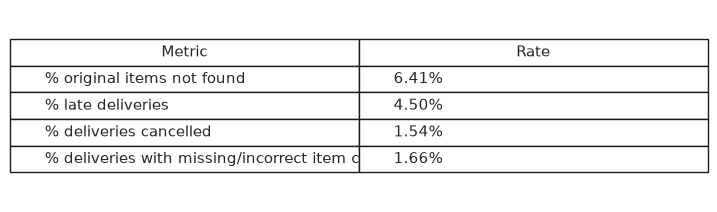

In [5]:
table_data = overview[["Metric", "Rate"]]

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.axis("off")

table = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc="left",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

# plt.savefig("delivery_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Current landscape

### Item volume by store

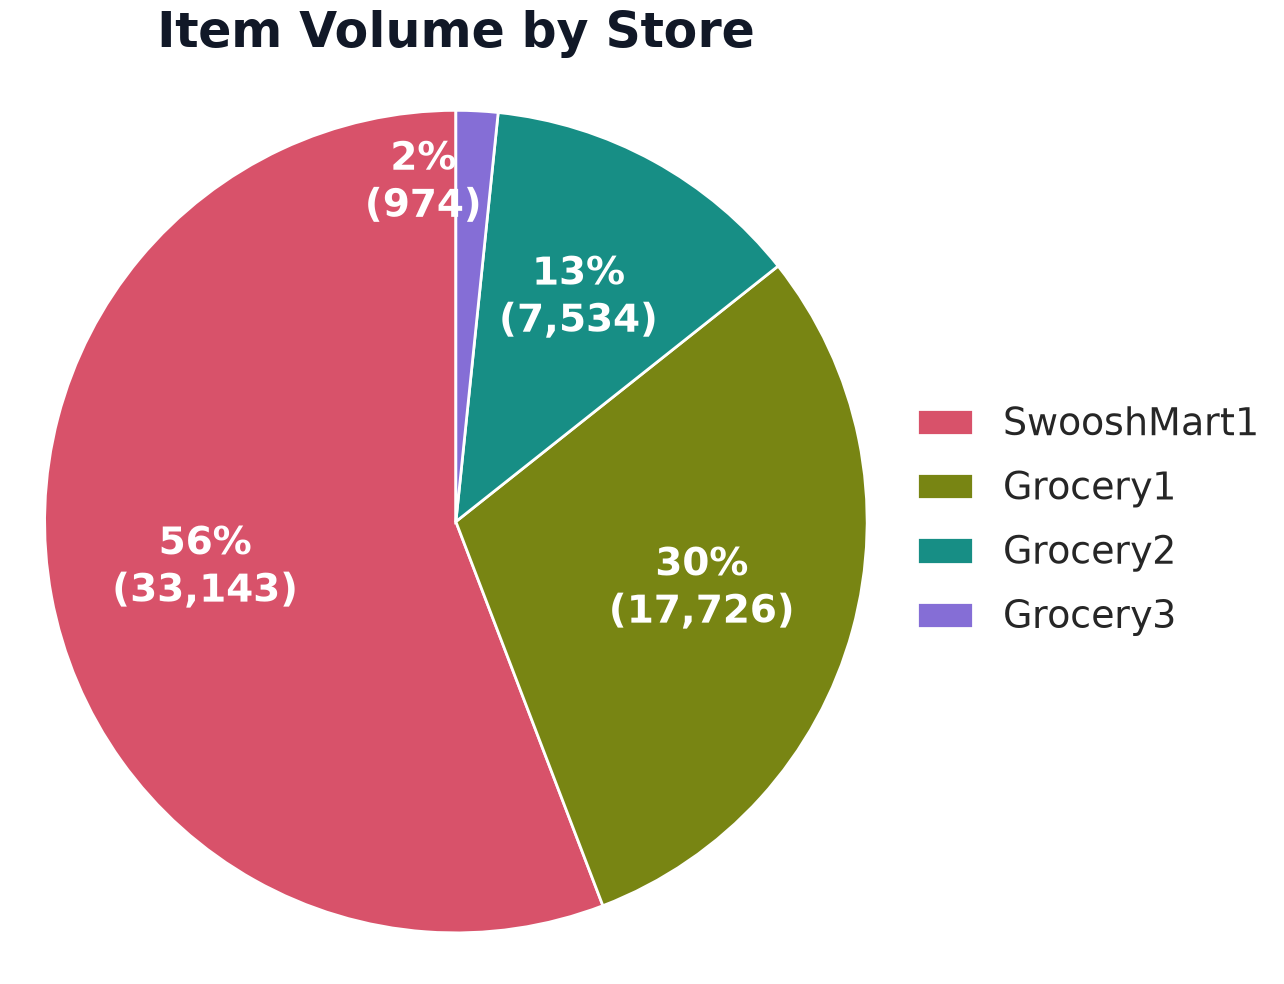

In [6]:
store_item_volume = (
    data.dropna(subset=["DELIV_STORE_NAME"])
    .groupby("DELIV_STORE_NAME", as_index=False)
    .size()
    .rename(columns={"size": "Total items", "DELIV_STORE_NAME": "Store"})
    .sort_values("Total items", ascending=False)
)

total_store_items = int(store_item_volume["Total items"].sum())

fig, ax = plt.subplots(figsize=(13, 10))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

palette = sns.color_palette("husl", n_colors=len(store_item_volume))
colors = [tuple(max(0, c - 0.12) for c in color) for color in palette]

wedges, _, autotexts = ax.pie(
    store_item_volume["Total items"],
    labels=None,
    autopct=lambda pct: f"{pct:.0f}%\n({int(round(pct / 100 * total_store_items)):,})",
    startangle=90,
    counterclock=True,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 18, "color": "#1f2937"},
    pctdistance=0.62,
    radius=1.08,
)

for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(28)
    autotext.set_fontweight("bold")
    autotext.set_ha("center")
    autotext.set_va("center")
    # Place a very small slice label above the pie to prevent overlap.
    if store_item_volume.iloc[list(autotexts).index(autotext)]["Total items"] / total_store_items < 0.03:
        x, y = autotext.get_position()
        autotext.set_position((x - 0.12, y + 0.22))
        autotext.set_color("white")
        # autotext.set_fontsize(20)
legend_labels = [row["Store"] for _, row in store_item_volume.iterrows()]
ax.legend(
    wedges,
    legend_labels,
    loc="center left",
    bbox_to_anchor=(1.00, 0.5),
    frameon=False,
    fontsize=27,
    title_fontsize=13,
    borderaxespad=0.0,
    labelspacing=0.7,
    handletextpad=0.8,
    handlelength=1.5,
)

ax.set_title(
    "Item Volume by Store",
    fontsize=35,
    fontweight="bold",
    color="#111827",
    pad=16,
)

ax.axis("equal")
plt.tight_layout()
plt.show()


### Item volume by category

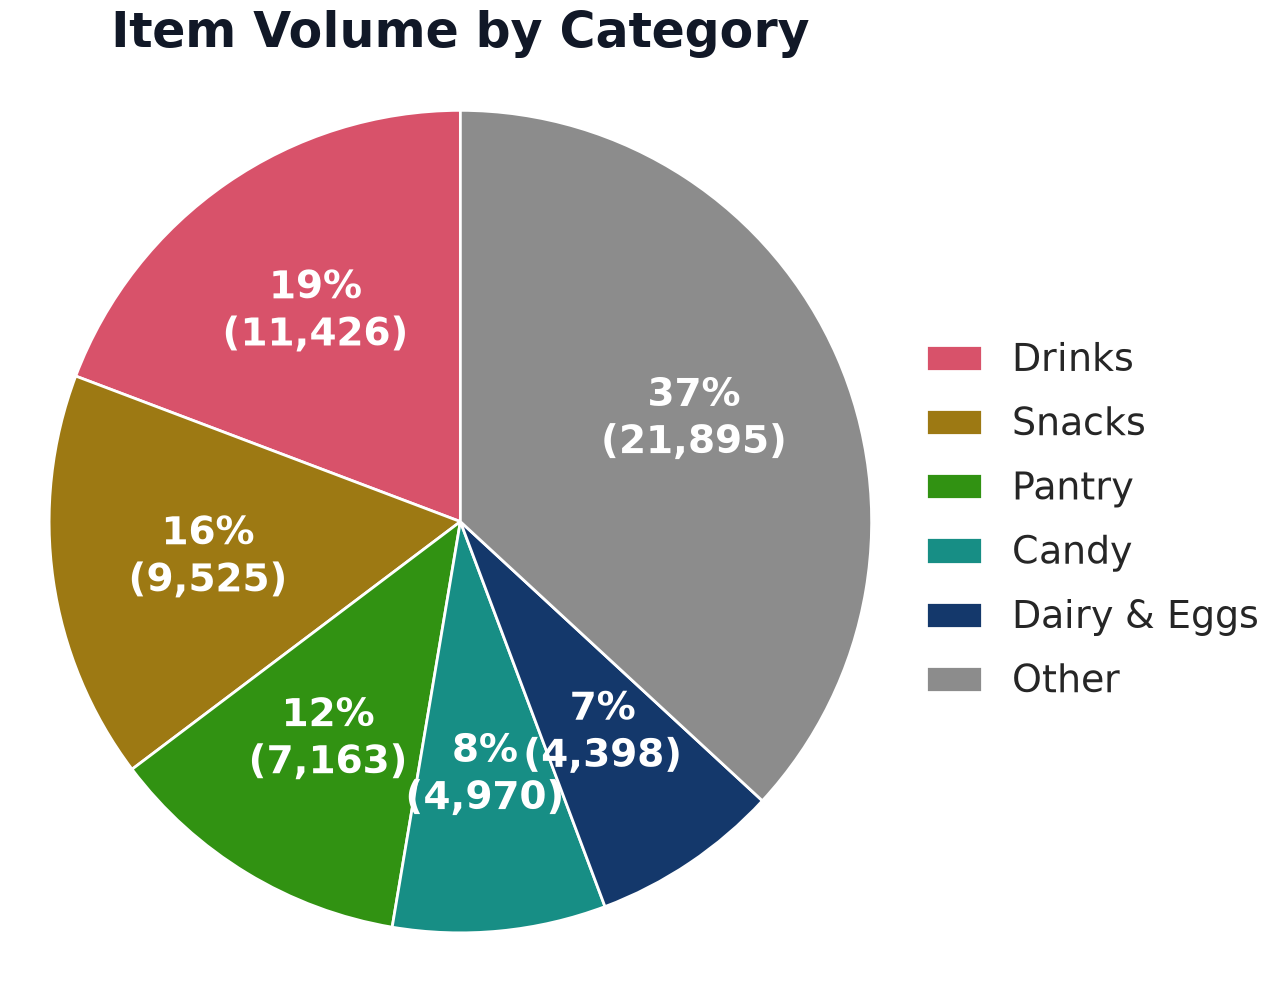

In [7]:
category_item_volume = (
    data.dropna(subset=["ITEM_CATEGORY"])
    .groupby("ITEM_CATEGORY", as_index=False)
    .size()
    .rename(columns={"size": "Total items", "ITEM_CATEGORY": "Category"})
    .sort_values("Total items", ascending=False)
)

if len(category_item_volume) > 5:
    top_categories = category_item_volume.head(5).copy()
    other_total = category_item_volume.iloc[5:]["Total items"].sum()
    category_item_volume = pd.concat(
        [top_categories, pd.DataFrame([{"Category": "Other", "Total items": other_total}])],
        ignore_index=True,
    )
fig, ax = plt.subplots(figsize=(13, 10))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

palette = sns.color_palette("husl", n_colors=len(category_item_volume))
colors = [tuple(max(0, c - 0.12) for c in color) for color in palette]
if len(category_item_volume) > 0:
    colors[-1] = (0.55, 0.55, 0.55)
for i, category_name in enumerate(category_item_volume["Category"]):
    if category_name == "Dairy & Eggs":
        colors[i] = (0.08, 0.22, 0.42)
wedges, _, autotexts = ax.pie(
    category_item_volume["Total items"],
    labels=None,
    autopct=lambda pct: f"{int(round(pct))}%\n({int(round(pct / 100 * category_item_volume['Total items'].sum())):,})",
    startangle=90,
    counterclock=True,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 18, "color": "#1f2937"},
    pctdistance=0.62,
    radius=1.08,
)

for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(28)
    autotext.set_fontweight("bold")
    autotext.set_ha("center")
    autotext.set_va("center")
    if autotext.get_text().startswith("1%"):
        x, y = autotext.get_position()
        autotext.set_position((x, y + 0.25))
legend_labels = [row["Category"] for _, row in category_item_volume.iterrows()]
ax.legend(
    wedges,
    legend_labels,
    loc="center left",
    bbox_to_anchor=(1.00, 0.5),
    frameon=False,
    fontsize=27,
    title_fontsize=13,
    borderaxespad=0.0,
    labelspacing=0.7,
    handletextpad=0.8,
    handlelength=1.5,
)

ax.set_title(
    "Item Volume by Category",
    fontsize=35,
    fontweight="bold",
    color="#111827",
    pad=16,
)

ax.axis("equal")
plt.tight_layout()
plt.show()


### Delivery volume by hour and day of week

In [8]:
delivery_by_hour = delivery_table.dropna(subset=["DELIV_CREATED_AT_ET"]).copy()
delivery_by_hour["Hour of day ET"] = delivery_by_hour["DELIV_CREATED_AT_ET"].dt.hour
hour_order = list(range(8, 24)) + list(range(0, 8))
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


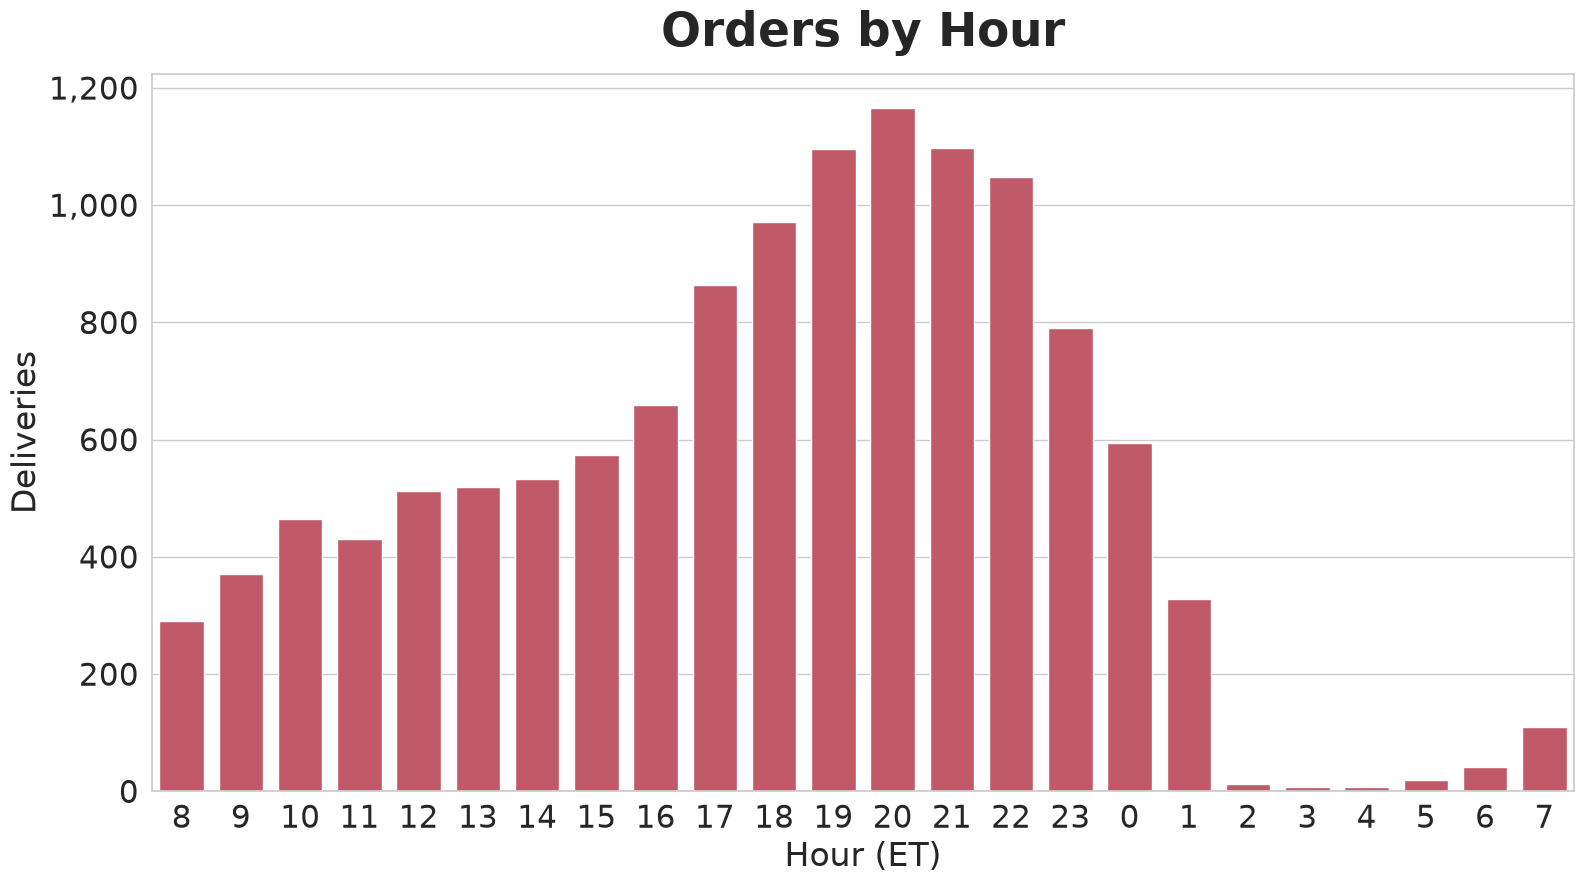

In [9]:
hourly_delivery_summary = (
    delivery_by_hour["Hour of day ET"].value_counts().sort_index().reset_index()
)
hourly_delivery_summary.columns = ["Hour", "Deliveries"]

ordered_hours = list(range(8, 24)) + list(range(0, 8))
hourly_delivery_summary = (
    hourly_delivery_summary.set_index("Hour")
    .reindex(ordered_hours, fill_value=0)
    .reset_index()
    .rename(columns={"index": "Hour"})
)

plt.figure(figsize=(16, 9))
ax = sns.barplot(
    data=hourly_delivery_summary,
    x=pd.Categorical(hourly_delivery_summary["Hour"], categories=ordered_hours),
    y="Deliveries",
    color="#D1495B",
    width=0.75,
)

ax.set_title("Orders by Hour", fontsize=34, fontweight="bold", pad=20)
ax.set_xlabel("Hour (ET)", fontsize=24)
ax.set_ylabel("Deliveries", fontsize=24)
ax.tick_params(axis="x", labelsize=22)
ax.tick_params(axis="y", labelsize=22)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{int(value):,}"))

plt.tight_layout()
plt.show()


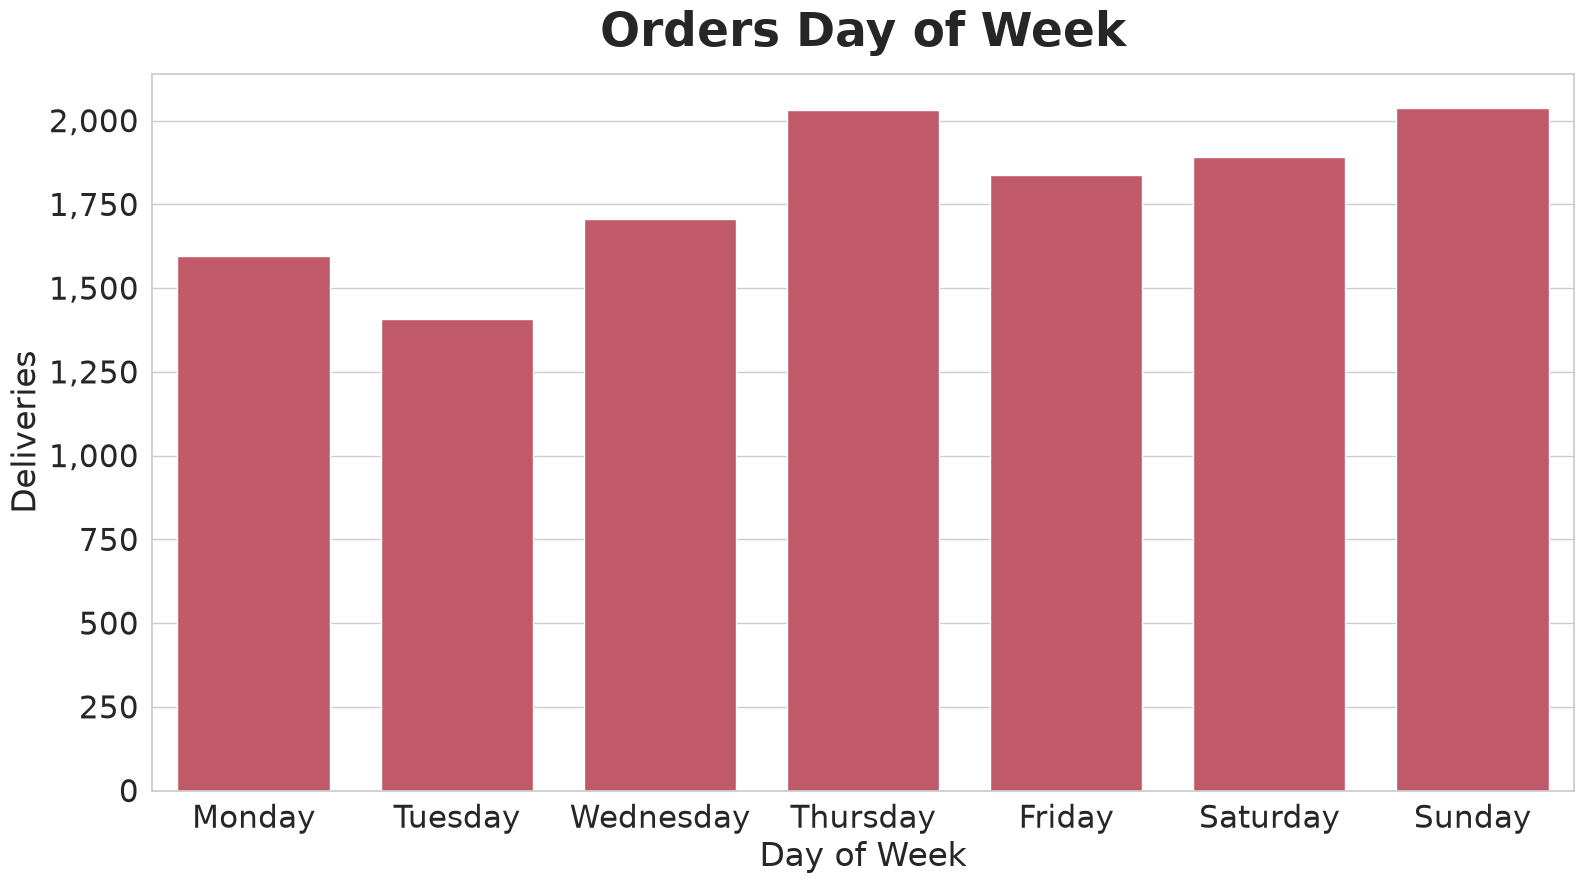

In [10]:
day_counts = (
    delivery_by_hour.dropna(subset=["DELIV_CREATED_AT_ET"])
    .copy()
    .assign(**{"Day of week": lambda df: df["DELIV_CREATED_AT_ET"].dt.day_name()})
)

day_of_week_summary = (
    day_counts["Day of week"]
    .value_counts()
    .reindex(day_order, fill_value=0)
    .rename_axis("Day of week")
    .reset_index(name="Deliveries")
)

plt.figure(figsize=(16, 9))
ax = sns.barplot(
    data=day_of_week_summary,
    x="Day of week",
    y="Deliveries",
    color="#D1495B",
    width=0.75,
    order=day_order,
)

ax.set_title("Orders Day of Week", fontsize=34, fontweight="bold", pad=20)
ax.set_xlabel("Day of Week", fontsize=24)
ax.set_ylabel("Deliveries", fontsize=24)
ax.tick_params(axis="x", labelsize=22)
ax.tick_params(axis="y", labelsize=22)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{int(value):,}"))

plt.tight_layout()
plt.show()


## 4. Original items missing

### Overall item fulfillment

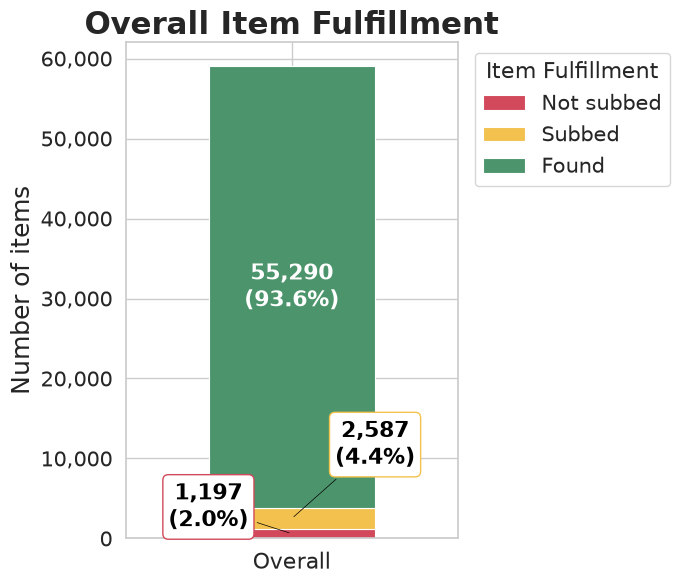

In [11]:
overall_item_outcomes = pd.DataFrame(
    {
        "Not subbed": [int(data["item_not_subbed"].sum())],
        "Subbed": [int(data["item_subbed"].sum())],
        "Found": [int(data["item_found"].sum())],
    },
    index=["Overall"],
)

overall_outcome_order = ["Not subbed", "Subbed", "Found"]
overall_outcome_colors = ["#D1495B", "#F2C14E", "#4C956C"]

overall_classified_items = overall_item_outcomes[overall_outcome_order].sum(axis=1).iloc[0]

overall_outcome_axis = overall_item_outcomes[overall_outcome_order].plot(
    kind="bar",
    stacked=True,
    figsize=(7, 6),
    color=overall_outcome_colors,
    edgecolor="white",
    linewidth=0.8,
)

overall_delivered_container = overall_outcome_axis.containers[2]

overall_outcome_axis.bar_label(
    overall_delivered_container,
    labels=[
        f"{value:,.0f}\n({value / overall_classified_items * 100:.1f}%)"
        for value in overall_item_outcomes["Found"]
    ],
    label_type="center",
    color="white",
    fontsize=16,
    fontweight="bold",
)

overall_not_subbed = overall_item_outcomes.loc["Overall", "Not subbed"]
overall_subbed = overall_item_outcomes.loc["Overall", "Subbed"]

overall_outcome_axis.annotate(
    f"{overall_not_subbed:,.0f}\n"
    f"({overall_not_subbed / overall_classified_items * 100:.1f}%)",
    xy=(0, overall_not_subbed / 2),
    xytext=(-60, 0),
    textcoords="offset points",
    ha="center",
    va="bottom",
    color="black",
    fontsize=16,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "#D1495B"},
    arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.5},
)

overall_outcome_axis.annotate(
    f"{overall_subbed:,.0f}\n"
    f"({overall_subbed / overall_classified_items * 100:.1f}%)",
    xy=(0, int(overall_not_subbed) + int(overall_subbed) / 2),
    xytext=(60, 34),
    textcoords="offset points",
    ha="center",
    va="bottom",
    color="black",
    fontsize=16,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "#F2C14E"},
    arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.5},
)

overall_outcome_axis.yaxis.set_major_formatter(
    lambda value, position: f"{value:,.0f}"
)

overall_outcome_axis.tick_params(axis="both", labelsize=15)

plt.xlabel("", fontsize=18)
plt.ylabel("Number of items", fontsize=18)
plt.title("Overall Item Fulfillment", fontsize=22, fontweight="bold")
plt.xticks(rotation=0, fontsize=16)
plt.legend(
    title="Item Fulfillment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=15,
    title_fontsize=16,
)

plt.tight_layout()
plt.show()


### Item fulfillment by store

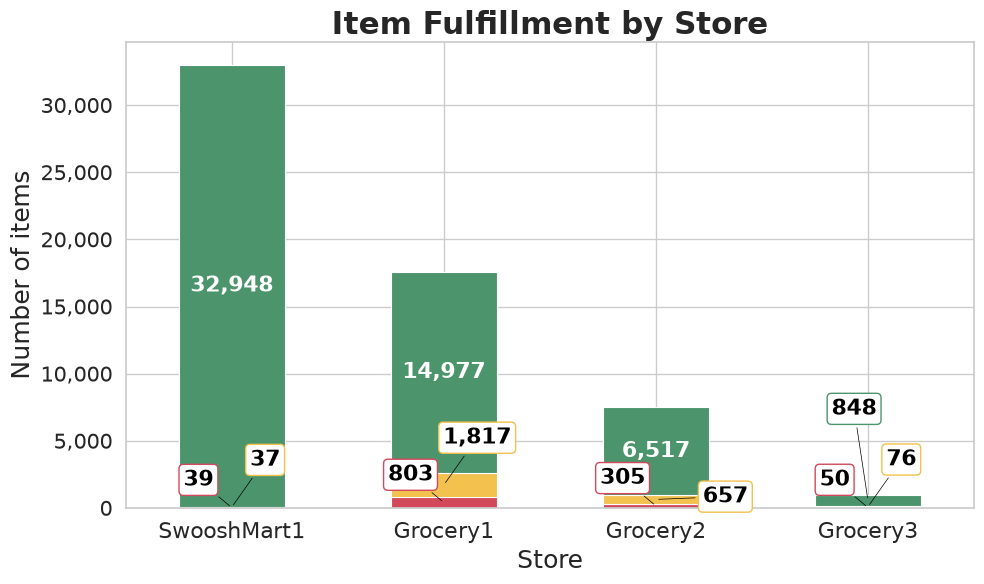

In [12]:
store_item_outcomes = (
    data.dropna(subset=["DELIV_STORE_NAME"])
    .groupby("DELIV_STORE_NAME")[["item_not_subbed", "item_subbed", "item_found"]]
    .sum()
    .astype(int)
    .rename(columns={
        "item_not_subbed": "Not subbed",
        "item_subbed": "Subbed",
        "item_found": "Delivered",
    })
)

store_order = ["SwooshMart1", "Grocery1", "Grocery2", "Grocery3"]
store_item_outcomes = store_item_outcomes.reindex(store_order)

outcome_order = ["Not subbed", "Subbed", "Delivered"]
outcome_colors = ["#D1495B", "#F2C14E", "#4C956C"]

outcome_axis = store_item_outcomes[outcome_order].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=outcome_colors,
    edgecolor="white",
    linewidth=0.8,
    legend=False
)

delivered_container = outcome_axis.containers[2]

outcome_axis.bar_label(
    delivered_container,
    labels=[
        "" if store_name == "Grocery3" else f"{value:,.0f}"
        for store_name, value in store_item_outcomes["Delivered"].items()
    ],
    label_type="center",
    color="white",
    fontsize=16,
    fontweight="bold",
)

for position, (store_name, outcomes) in enumerate(store_item_outcomes.iterrows()):
    not_subbed = outcomes["Not subbed"]
    subbed = outcomes["Subbed"]
    delivered = outcomes["Delivered"]
    subbed_offset = (50, -6) if store_name == "Grocery2" else (24, 26)
    outcome_axis.annotate(
        f"{not_subbed:,.0f}",
        xy=(position, not_subbed / 2),
        xytext=(-24, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color="black",
        fontsize=16,
        fontweight="bold",
        bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "#D1495B"},
        arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.5},
    )
    outcome_axis.annotate(
        f"{subbed:,.0f}",
        xy=(position, not_subbed + subbed / 2),
        xytext=subbed_offset,
        textcoords="offset points",
        ha="center",
        va="bottom",
        color="black",
        fontsize=16,
        fontweight="bold",
        bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "#F2C14E"},
        arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.5},
    )
    if store_name == "Grocery3":
        outcome_axis.annotate(
            f"{delivered:,.0f}",
            xy=(position, not_subbed + subbed + delivered / 2),
            xytext=(-10, 58),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color="black",
            fontsize=16,
            fontweight="bold",
            bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "#4C956C"},
            arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.5},
        )
outcome_axis.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")

outcome_axis.tick_params(axis="both", labelsize=15)

plt.xlabel("Store", fontsize=18)
plt.ylabel("Number of items", fontsize=18)
plt.title("Item Fulfillment by Store", fontsize=22, fontweight="bold")
plt.xticks(rotation=0, fontsize=16)

plt.tight_layout()
plt.show()


### Original items missing by hour (Eastern Time)

In [13]:
# Aggregate all item records into the three item-fulfillment outcomes.
time_of_day_item_outcomes = (
    data.dropna(subset=["DELIV_CREATED_AT_ET"])
    .groupby(data["DELIV_CREATED_AT_ET"].dt.hour)[
        ["item_found", "item_subbed", "item_not_subbed"]
    ]
    .sum()
    .reindex(hour_order, fill_value=0)
    .rename(columns={
        "item_found": "Delivered",
        "item_subbed": "Subbed",
        "item_not_subbed": "Not subbed",
    })
    .astype(int)
)
time_of_day_item_outcomes.index = [f"{hour}:00" for hour in hour_order]


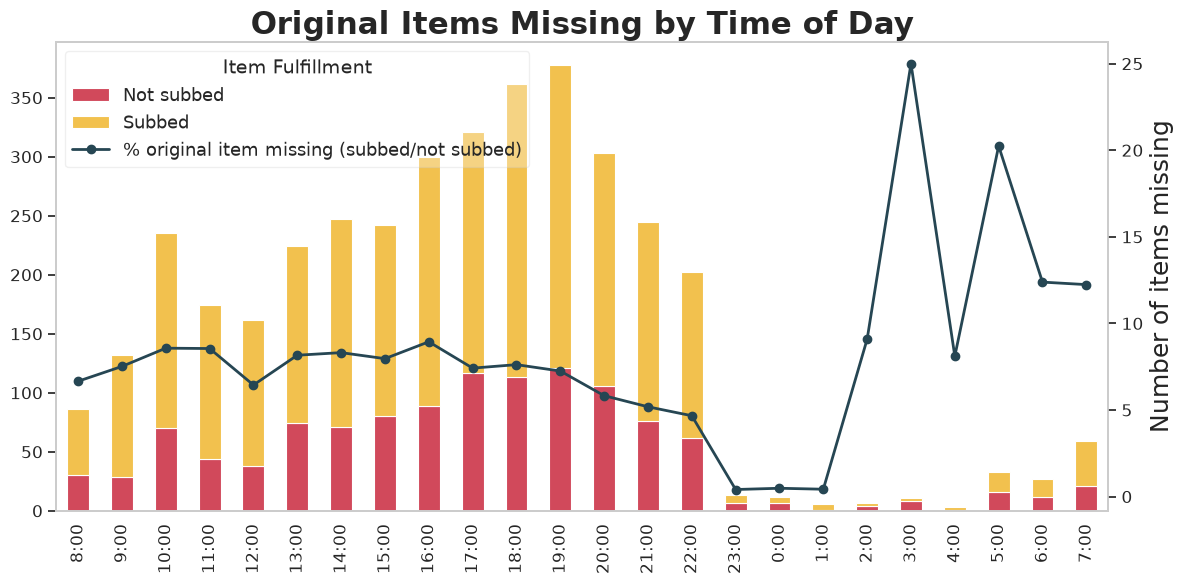

In [14]:
outcome_order = ["Not subbed", "Subbed"]
outcome_colors = ["#D1495B", "#F2C14E"]

outcome_axis = time_of_day_item_outcomes[outcome_order].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=outcome_colors,
    edgecolor="white",
    linewidth=0.8,
)

outcome_axis.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
outcome_axis.tick_params(axis="both", labelsize=12)
outcome_axis.grid(False)

pct_missing_axis = outcome_axis.twinx()
pct_missing_by_time = (
    time_of_day_item_outcomes["Not subbed"] + time_of_day_item_outcomes["Subbed"]
) / time_of_day_item_outcomes[["Delivered", "Subbed", "Not subbed"]].sum(axis=1) * 100

pct_missing_axis.plot(
    range(len(pct_missing_by_time)),
    pct_missing_by_time,
    color="#264653",
    marker="o",
    linewidth=2,
    label="% original item missing (subbed/not subbed)",
)
pct_missing_axis.set_ylabel("% original item missing (subbed/not subbed)", fontsize=14)
pct_missing_axis.tick_params(axis="y", labelsize=12)
pct_missing_axis.grid(False)

plt.xlabel("Time of day (ET)", fontsize=18)
plt.ylabel("Number of items missing", fontsize=18)
plt.title("Original Items Missing by Time of Day", fontsize=22, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=12)

bar_handles, bar_labels = outcome_axis.get_legend_handles_labels()
line_handles, line_labels = pct_missing_axis.get_legend_handles_labels()
outcome_axis.legend(
    bar_handles + line_handles,
    bar_labels + line_labels,
    title="Item Fulfillment",
    loc="upper left",
    fontsize=13,
    title_fontsize=14,
    framealpha=0.3,
)
plt.tight_layout()
plt.show()


### Original items missing by item category

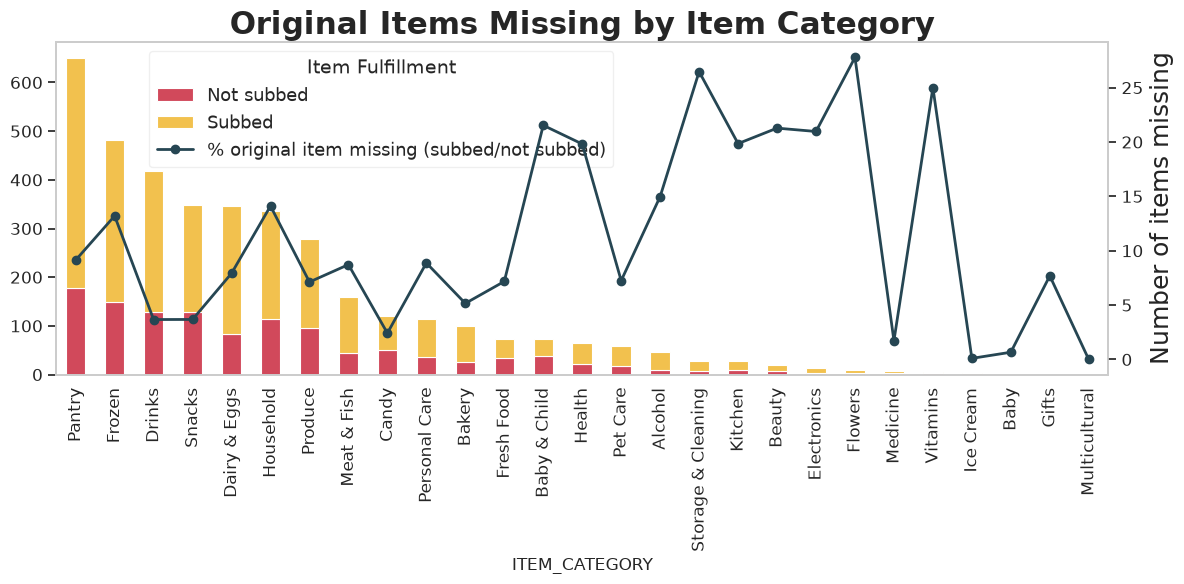

In [15]:
outcome_order = ["Not subbed", "Subbed"]
outcome_colors = ["#D1495B", "#F2C14E"]

category_item_outcomes = (
    data.dropna(subset=["ITEM_CATEGORY"])
    .assign(
        Delivered=lambda frame: frame["WAS_FOUND"].eq(True).fillna(False),
        Subbed=lambda frame: (
            frame["WAS_FOUND"].eq(False)
            & frame["WAS_MISSING"].eq(True)
            & frame["WAS_SUBBED"].eq(True)
        ).fillna(False),
        **{
            "Not subbed": lambda frame: (
                frame["WAS_FOUND"].eq(False)
                & frame["WAS_MISSING"].eq(True)
                & frame["WAS_SUBBED"].eq(False)
            ).fillna(False)
        },
    )
    .groupby("ITEM_CATEGORY")[["Delivered", "Subbed", "Not subbed"]]
    .sum()
    .astype(int)
)

category_missing_order = (
    (category_item_outcomes["Not subbed"] + category_item_outcomes["Subbed"])
    .sort_values(ascending=False)
    .index
)
category_item_outcomes = category_item_outcomes.loc[category_missing_order]

outcome_axis = category_item_outcomes[outcome_order].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=outcome_colors,
    edgecolor="white",
    linewidth=0.8,
)

outcome_axis.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
outcome_axis.tick_params(axis="both", labelsize=12)
outcome_axis.grid(False)

pct_missing_axis = outcome_axis.twinx()
pct_missing_by_category = (
    category_item_outcomes["Not subbed"] + category_item_outcomes["Subbed"]
) / category_item_outcomes[["Delivered", "Subbed", "Not subbed"]].sum(axis=1) * 100

pct_missing_axis.plot(
    range(len(pct_missing_by_category)),
    pct_missing_by_category,
    color="#264653",
    marker="o",
    linewidth=2,
    label="% original item missing (subbed/not subbed)",
)
pct_missing_axis.set_ylabel("% original item missing (subbed/not subbed)", fontsize=14)
pct_missing_axis.tick_params(axis="y", labelsize=12)
pct_missing_axis.grid(False)

plt.xlabel("", fontsize=18)
plt.ylabel("Number of items missing", fontsize=18)
plt.title("Original Items Missing by Item Category", fontsize=22, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=12)

bar_handles, bar_labels = outcome_axis.get_legend_handles_labels()
line_handles, line_labels = pct_missing_axis.get_legend_handles_labels()
outcome_axis.legend(
    bar_handles + line_handles,
    bar_labels + line_labels,
    title="Item Fulfillment",
    loc="upper left",
    bbox_to_anchor=(0.08, 1),
    fontsize=13,
    title_fontsize=14,
    framealpha=0.3,
)
plt.tight_layout()
plt.show()


## 5. Late deliveries

### Late delivery rate by store

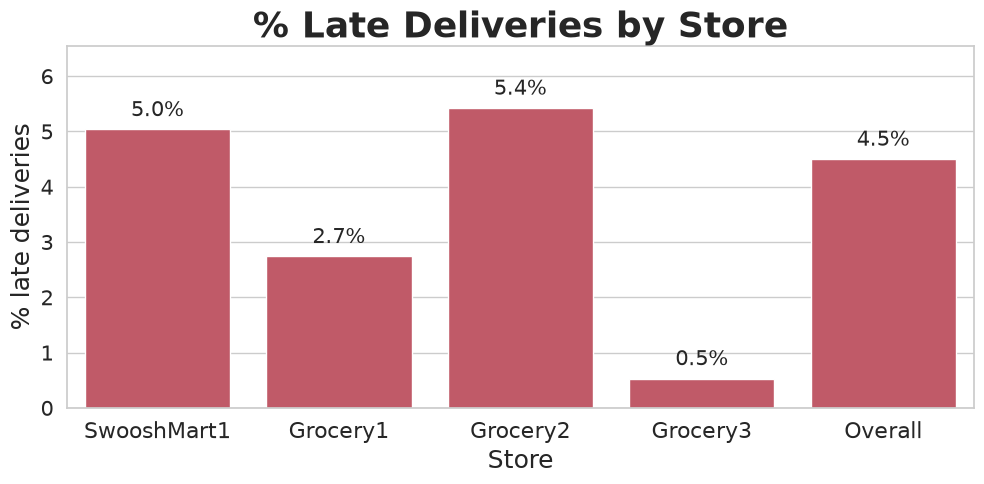

In [16]:
pct_late_by_store = (
    delivery_table.dropna(subset=["DELIV_IS_20_MIN_LATE", "DELIV_STORE_NAME"])
    .groupby("DELIV_STORE_NAME", as_index=False)["DELIV_IS_20_MIN_LATE"]
    .mean()
)

pct_late_by_store["DELIV_IS_20_MIN_LATE"] = pct_late_by_store["DELIV_IS_20_MIN_LATE"] * 100

overall_pct_late = (
    delivery_table["DELIV_IS_20_MIN_LATE"].dropna().mean() * 100
)

pct_late_by_store = pd.concat(
    [
        pct_late_by_store,
        pd.DataFrame(
            {
                "DELIV_STORE_NAME": ["Overall"],
                "DELIV_IS_20_MIN_LATE": [overall_pct_late],
            }
        ),
    ],
    ignore_index=True,
)

plt.figure(figsize=(10, 5))

late_store_axis = sns.barplot(
    color="#D1495B",
    data=pct_late_by_store,
    x="DELIV_STORE_NAME",
    y="DELIV_IS_20_MIN_LATE",
    order=["SwooshMart1", "Grocery1", "Grocery2", "Grocery3", "Overall"],
)

for bar in late_store_axis.patches:
    late_store_axis.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=15,
    )
late_store_axis.set_ylim(0, late_store_axis.get_ylim()[1] * 1.15)

plt.xlabel("Store", fontsize=18)
plt.ylabel("% late deliveries", fontsize=18)
plt.title("% Late Deliveries by Store", fontsize=26, fontweight="bold")
plt.xticks(fontsize=16)
plt.yticks(fontsize=15)
plt.tight_layout()
plt.show()


### Late deliveries by hour (Eastern Time)

In [17]:
hourly_delivery_summary = (
    delivery_by_hour.groupby("Hour of day ET")
    .agg(
        total_deliveries=("DELIVERY_UUID", "count"),
        late_deliveries=("DELIV_IS_20_MIN_LATE", lambda values: int(values.fillna(False).eq(True).sum())),
    )
    .reindex(hour_order, fill_value=0)
    .reset_index()
)

hourly_delivery_summary["pct_late_deliveries"] = np.where(
    hourly_delivery_summary["total_deliveries"].gt(0),
    hourly_delivery_summary["late_deliveries"] / hourly_delivery_summary["total_deliveries"] * 100,
    0,
)


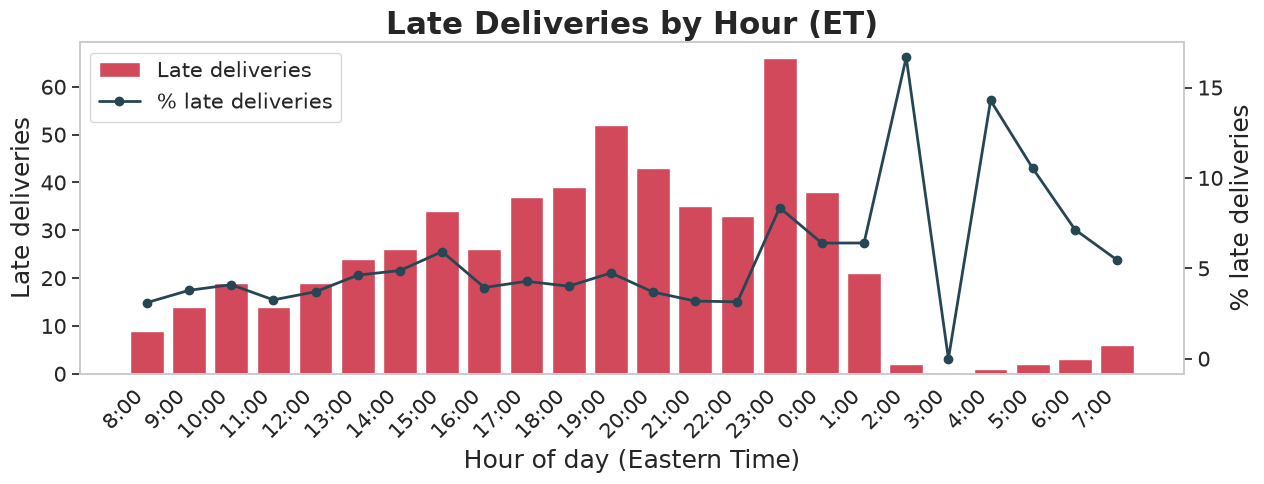

In [18]:
late_x_positions = np.arange(len(hourly_delivery_summary))
late_hour_labels = [f"{hour}:00" for hour in hourly_delivery_summary["Hour of day ET"]]

fig, total_axis = plt.subplots(figsize=(13, 5))
late_axis = total_axis.twinx()

total_bars = total_axis.bar(
    late_x_positions,
    hourly_delivery_summary["late_deliveries"],
    label="Late deliveries",
    color="#D1495B",
)
late_line = late_axis.plot(
    late_x_positions,
    hourly_delivery_summary["pct_late_deliveries"],
    color="#264653",
    marker="o",
    linewidth=2,
    label="% late deliveries",
)

total_axis.set_xlabel("Hour of day (Eastern Time)", fontsize=18)
total_axis.set_ylabel("Late deliveries", fontsize=18)
late_axis.set_ylabel("% late deliveries", fontsize=18)
total_axis.set_title(
    "Late Deliveries by Hour (ET)",
    fontsize=22,
    fontweight="bold",
)
total_axis.set_xticks(late_x_positions)
total_axis.set_xticklabels(late_hour_labels, rotation=45, ha="right", fontsize=15)
total_axis.tick_params(axis="y", labelsize=15)
late_axis.tick_params(axis="y", labelsize=15)
total_axis.grid(False)
late_axis.grid(False)

bars, labels = total_axis.get_legend_handles_labels()
lines, line_labels = late_axis.get_legend_handles_labels()
total_axis.legend(
    bars + lines,
    labels + line_labels,
    loc="upper left",
    fontsize=15,
)

plt.tight_layout()
plt.show()


### Delivery CLAT and D2R by late-delivery status

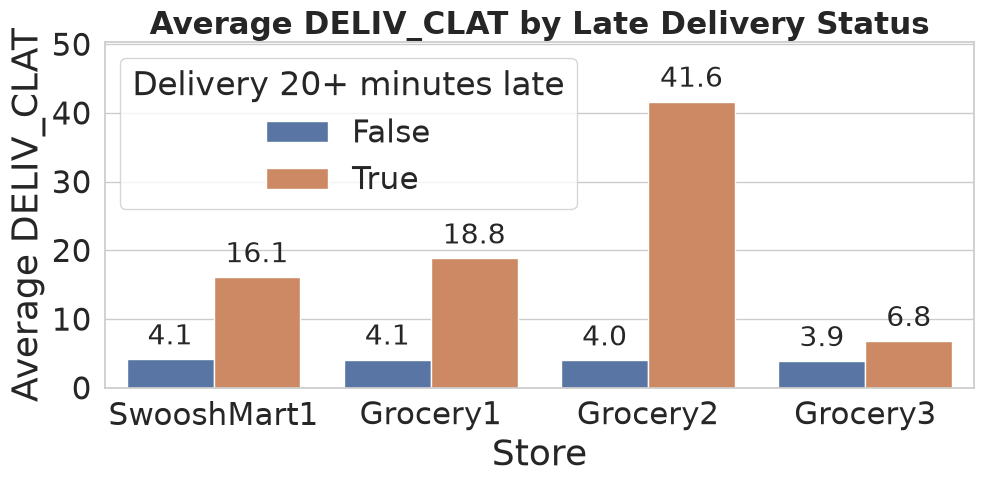

In [19]:
plt.figure(figsize=(10, 5))

clat_store_axis = sns.barplot(
    data=delivery_table.dropna(subset=["DELIV_IS_20_MIN_LATE", "DELIV_CLAT", "DELIV_STORE_NAME"]),
    x="DELIV_STORE_NAME",
    y="DELIV_CLAT",
    hue="DELIV_IS_20_MIN_LATE",
    estimator="mean",
    errorbar=None,
)
for bar in clat_store_axis.patches:
    if bar.get_height() > 0:
        clat_store_axis.annotate(
            f"{bar.get_height():.1f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=20,
        )
clat_store_axis.set_ylim(0, clat_store_axis.get_ylim()[1] * 1.15)

plt.xlabel("Store", fontsize=26)
plt.ylabel("Average DELIV_CLAT", fontsize=26)
plt.title(
    "Average DELIV_CLAT by Late Delivery Status",
    fontsize=22,
    fontweight="bold",
)
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
plt.legend(
    title="Delivery 20+ minutes late",
    fontsize=22,
    title_fontsize=24,
)
plt.tight_layout()
plt.show()


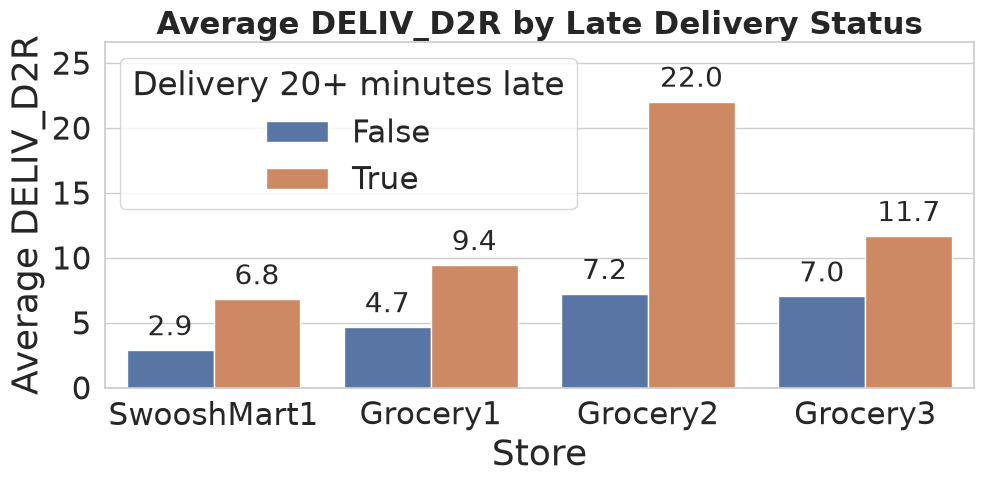

In [20]:
plt.figure(figsize=(10, 5))

d2r_store_axis = sns.barplot(
    data=delivery_table.dropna(subset=["DELIV_IS_20_MIN_LATE", "DELIV_D2R", "DELIV_STORE_NAME"]),
    x="DELIV_STORE_NAME",
    y="DELIV_D2R",
    hue="DELIV_IS_20_MIN_LATE",
    estimator="mean",
    errorbar=None,
)

for bar in d2r_store_axis.patches:
    if bar.get_height() > 0:
        d2r_store_axis.annotate(
            f"{bar.get_height():.1f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=20,
        )
d2r_store_axis.set_ylim(0, d2r_store_axis.get_ylim()[1] * 1.15)

plt.xlabel("Store", fontsize=26)
plt.ylabel("Average DELIV_D2R", fontsize=26)
plt.title(
    "Average DELIV_D2R by Late Delivery Status",
    fontsize=22,
    fontweight="bold",
)
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
plt.legend(
    title="Delivery 20+ minutes late",
    fontsize=22,
    title_fontsize=24,
)
plt.tight_layout()
plt.show()


## 6. Order cancellations

### Cancellation rate by store

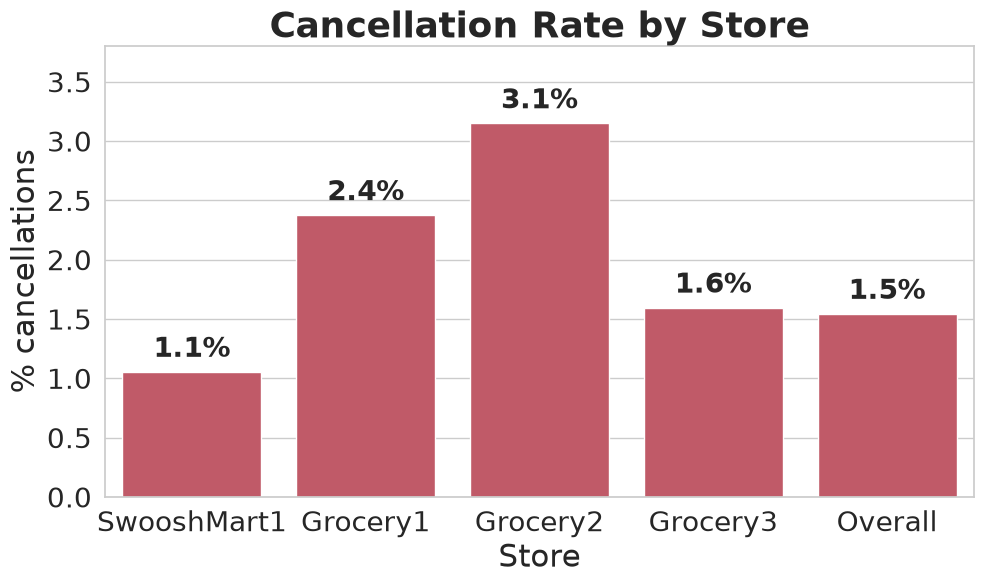

In [21]:
cancellation_rate_by_store = (
    delivery_table.dropna(subset=["DELIV_STORE_NAME"])
    .assign(is_cancelled=lambda frame: frame["DELIV_CANCELLED_AT"].notna())
    .groupby("DELIV_STORE_NAME", as_index=False)
    .agg(
        total_deliveries=("DELIVERY_UUID", "count"),
        cancelled_deliveries=("is_cancelled", "sum"),
    )
)

cancellation_rate_by_store["pct_cancellations"] = (
    cancellation_rate_by_store["cancelled_deliveries"]
    / cancellation_rate_by_store["total_deliveries"]
    * 100
)

overall_cancellation_rate = pd.DataFrame(
    {
        "DELIV_STORE_NAME": ["Overall"],
        "total_deliveries": [int(delivery_table["DELIVERY_UUID"].count())],
        "cancelled_deliveries": [int(delivery_table["DELIV_CANCELLED_AT"].notna().sum())],
        "pct_cancellations": [
            delivery_table["DELIV_CANCELLED_AT"].notna().mean() * 100
        ],
    }
)

cancellation_rate_by_store = pd.concat(
    [cancellation_rate_by_store, overall_cancellation_rate],
    ignore_index=True,
)

plt.figure(figsize=(10, 6))

cancellation_axis = sns.barplot(
    color="#D1495B",
    data=cancellation_rate_by_store,
    x="DELIV_STORE_NAME",
    y="pct_cancellations",
    order=["SwooshMart1", "Grocery1", "Grocery2", "Grocery3", "Overall"],
)

for bar in cancellation_axis.patches:
    cancellation_axis.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 6),
        textcoords="offset points",
        fontsize=20,
        fontweight="bold",
    )
cancellation_axis.set_ylim(0, cancellation_axis.get_ylim()[1] * 1.15)

plt.xlabel("Store", fontsize=22)
plt.ylabel("% cancellations", fontsize=22)
plt.title(
    "Cancellation Rate by Store",
    fontsize=26,
    fontweight="bold",
)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.show()


### Cumulative distribution of time to cancellation

In [22]:
delivery_table["time to cancellation (minutes)"] = (
    delivery_table["DELIV_CANCELLED_AT_ET"]
    - delivery_table["DELIV_CREATED_AT_ET"]
).dt.total_seconds() / 60
cancellation_times = delivery_table["time to cancellation (minutes)"].dropna()


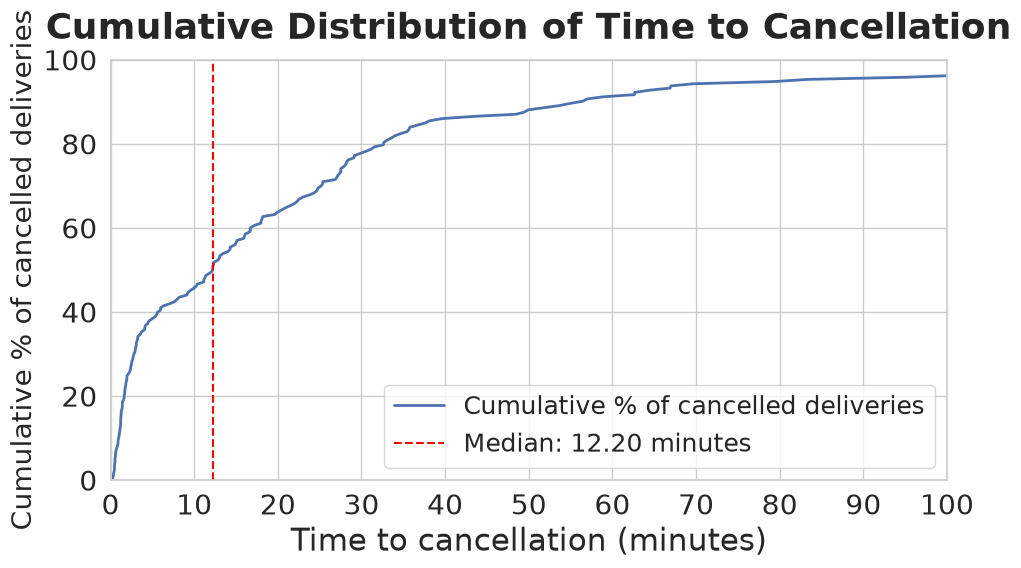

In [23]:
sorted_cancellation_times = np.sort(cancellation_times.to_numpy())
cumulative_percent = np.arange(1, len(sorted_cancellation_times) + 1) / len(sorted_cancellation_times) * 100

plt.figure(figsize=(10, 6.5))

plt.plot(
    sorted_cancellation_times,
    cumulative_percent,
    linewidth=2,
    label="Cumulative % of cancelled deliveries",
)

plt.axvline(
    cancellation_times.median(),
    color="red",
    linestyle="--",
    label=f"Median: {cancellation_times.median():.2f} minutes",
)

plt.xlabel("Time to cancellation (minutes)", fontsize=22)
plt.ylabel("Cumulative % of cancelled deliveries", fontsize=20)
plt.title(
    "Cumulative Distribution of Time to Cancellation",
    fontsize=26,
    fontweight="bold",
    y=1.03,
)
plt.xticks(np.arange(0, 101, 10), fontsize=20)
plt.yticks(fontsize=20)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend(fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


### Cancelled deliveries with missing original items

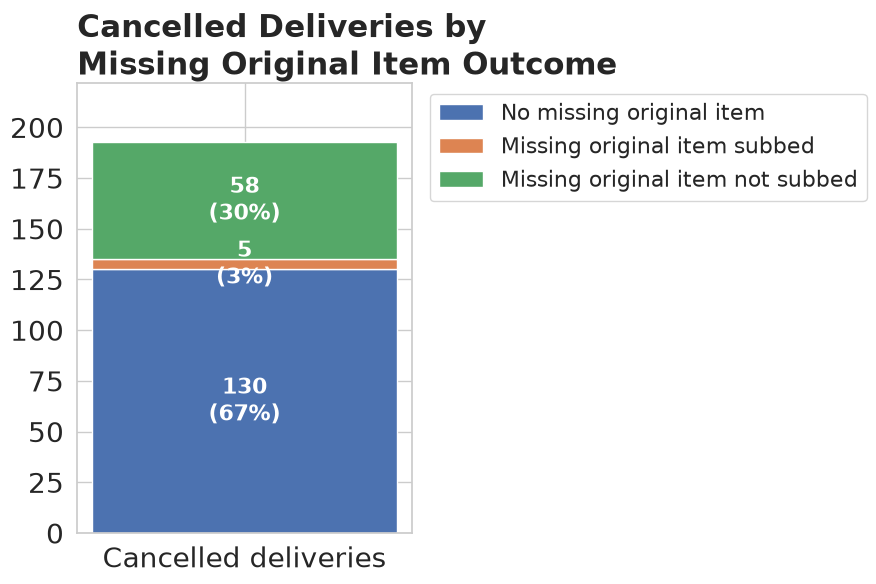

In [24]:
cancelled_delivery_outcomes = delivery_table.loc[
    delivery_table["DELIV_CANCELLED_AT"].notna()
].copy()

cancelled_delivery_outcomes["Cancellation category"] = np.select(
    [
        cancelled_delivery_outcomes["missing_without_replacement"].gt(0),
        cancelled_delivery_outcomes["missing_and_replaced"].gt(0),
    ],
    [
        "Missing original item not subbed",
        "Missing original item subbed",
    ],
    default="No missing original item",
)

cancellation_category_order = [
    "No missing original item",
    "Missing original item subbed",
    "Missing original item not subbed",
]

cancelled_delivery_summary = (
    cancelled_delivery_outcomes["Cancellation category"]
    .value_counts()
    .reindex(cancellation_category_order, fill_value=0)
)
total_cancelled_deliveries = int(cancelled_delivery_summary.sum())

plt.figure(figsize=(9, 6))

category_colors = sns.color_palette(n_colors=len(cancellation_category_order))
bottom = 0

for category, color in zip(cancellation_category_order, category_colors):
    value = int(cancelled_delivery_summary[category])
    plt.bar(
        ["Cancelled deliveries"],
        [value],
        bottom=bottom,
        label=category,
        color=color,
    )
    plt.text(
        0,
        bottom + value / 2,
        f"{value:,.0f}\n({value / total_cancelled_deliveries * 100:.0f}%)",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold",
        color="white",
    )
    bottom += value
plt.xlabel("", fontsize=22)
# plt.ylabel("Number of cancelled deliveries", fontsize=22)
plt.title(
    "Cancelled Deliveries by\nMissing Original Item Outcome",
    fontsize=22,
    fontweight="bold",
    loc="left",
)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=16,
    title_fontsize=17,
)
plt.ylim(0, bottom * 1.15)
plt.tight_layout()
plt.show()


### Cancellation timing when no original item was missing

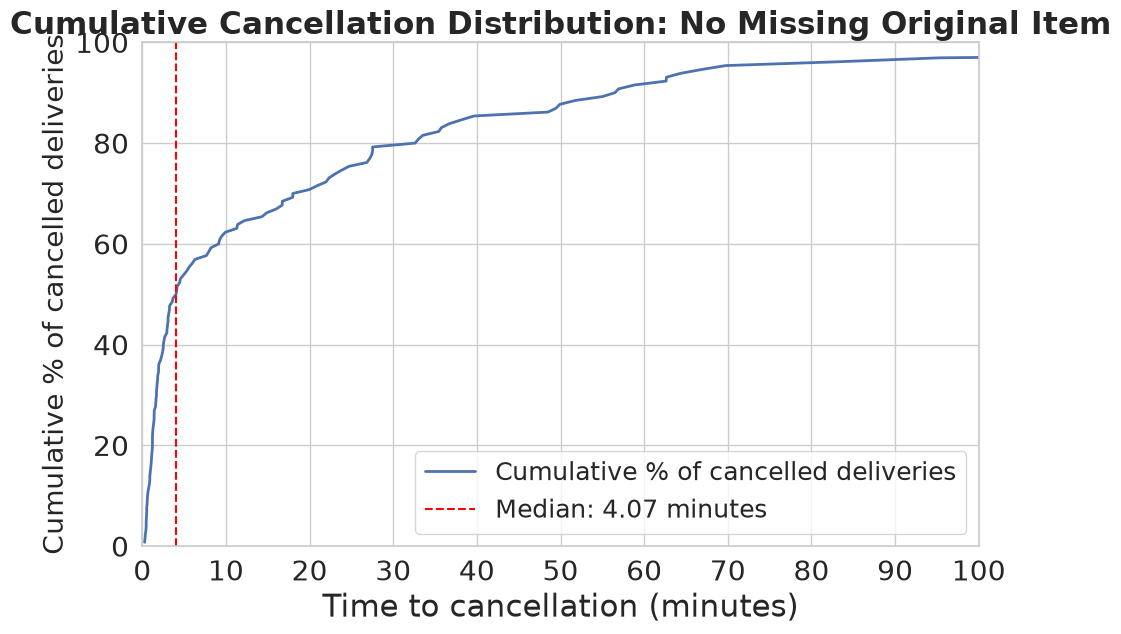

In [25]:
no_missing_cancelled_deliveries = delivery_table.loc[
    delivery_table["DELIV_CANCELLED_AT"].notna()
    & delivery_table["missing_and_replaced"].eq(0)
    & delivery_table["missing_without_replacement"].eq(0),
].copy()

no_missing_cancelled_deliveries["time to cancellation (minutes)"] = (
    no_missing_cancelled_deliveries["DELIV_CANCELLED_AT_ET"]
    - no_missing_cancelled_deliveries["DELIV_CREATED_AT_ET"]
).dt.total_seconds() / 60
no_missing_cancellation_times = no_missing_cancelled_deliveries[
    "time to cancellation (minutes)"
].dropna()

sorted_no_missing_cancellation_times = np.sort(
    no_missing_cancellation_times.to_numpy()
)
no_missing_cumulative_percent = (
    np.arange(1, len(sorted_no_missing_cancellation_times) + 1)
    / len(sorted_no_missing_cancellation_times)
    * 100
)
plt.figure(figsize=(10, 6.5))

plt.plot(
    sorted_no_missing_cancellation_times,
    no_missing_cumulative_percent,
    linewidth=2,
    label="Cumulative % of cancelled deliveries",
)
plt.axvline(
    no_missing_cancellation_times.median(),
    color="red",
    linestyle="--",
    label=f"Median: {no_missing_cancellation_times.median():.2f} minutes",
)
plt.xlabel("Time to cancellation (minutes)", fontsize=22)
plt.ylabel("Cumulative % of cancelled deliveries", fontsize=20)
plt.title(
    "Cumulative Cancellation Distribution: No Missing Original Item",
    fontsize=22,
    fontweight="bold",
)
plt.xticks(np.arange(0, 101, 10), fontsize=20)
plt.yticks(fontsize=20)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend(fontsize=18)
plt.tight_layout()
plt.show()


### Value of cancelled orders

In [26]:
cancelled_delivery_ids = delivery_table.loc[
    delivery_table["DELIV_CANCELLED_AT"].notna(), "DELIVERY_UUID"
]
cancelled_value = data.loc[
    data["DELIVERY_UUID"].isin(cancelled_delivery_ids), "ITEM_PRICE"
].sum()
print(f"Value of cancelled delivery items: ${cancelled_value:,.2f}")
print(f"Share of total item value: {cancelled_value / total_order_value * 100:.2f}%")


Value of cancelled delivery items: $3,140.15
Share of total item value: 1.11%
